<a href="https://colab.research.google.com/github/somanath-analyst/Amazon-Prime-TV-Shows-and-Movies/blob/main/Amazon_Prime_TV_Shows_and_Movies.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    -  Amazon Prime TV Shows and Movies






##### **Project Type**    - EDA/Regression/Classification/Unsupervised
##### **Contribution**    - Individual
##### **Name**            - Somanath R Shandage

# **Project Summary -**

This project focuses on analyzing the Amazon Prime Video content library using data analysis and visualization techniques. The dataset contains information about movies and TV shows available on Amazon Prime Video, including their release year, genre, age certification, runtime, production country, IMDb ratings, IMDb votes, and TMDB ratings and popularity.

The analysis aims to understand the content distribution, identify popular genres and production regions, examine trends in content released over the years, and study the relationship between ratings, popularity, and audience engagement. The project uses Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn for data cleaning, manipulation, exploratory data analysis, and visualization.

The insights obtained from this analysis can help understand Amazon Prime Video's content strategy, audience preferences, content quality, and areas that may support future content investment decisions.


# **GitHub Link -**

# **Problem Statement**


The objective of this project is to analyze the Amazon Prime Video dataset and understand the characteristics, trends, and patterns of the content available on the platform. The dataset contains information about movies and TV shows, including their genres, release years, age certifications, runtime, production countries, IMDb ratings, IMDb votes, and TMDB popularity and ratings.

The analysis aims to understand how Amazon Prime Video's content library is distributed across different categories and how it has evolved over time. It will identify the most common genres, major content-producing countries, and the distribution of Movies and TV Shows. The project will also examine audience-related metrics such as ratings, votes, and popularity to identify highly rated and popular content.

The analysis will further compare Movies and TV Shows based on factors such as runtime, ratings, popularity, and audience engagement. Relationships between different numerical and categorical variables will be explored using statistical analysis and visualizations.

The insights obtained from this analysis can help understand audience preferences, content diversity, quality, and changing trends in the streaming industry. These findings can support better content planning, investment decisions, audience targeting, and overall business strategy for streaming platforms.


#### **Define Your Business Objective?**

The primary business objective of this project is to analyze Amazon Prime Video's content library and identify insights that can support better content and business decisions.

The analysis aims to:

* Understand the distribution of Movies and TV Shows available on the platform.
* Identify popular genres and major content-producing countries.
* Analyze content growth and trends over different years.
* Identify highly rated and popular titles using IMDb and TMDB metrics.
* Understand the relationship between ratings, audience engagement, and popularity.
* Compare Movies and TV Shows based on their content characteristics and performance.
* Identify audience preferences based on age certification and content categories.

These insights can help streaming platforms understand audience interests, improve content selection and investment strategies, and identify opportunities for increasing user engagement and subscription growth.


# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [ ]:

# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress unnecessary warning messages
import warnings
warnings.filterwarnings('ignore')

# Set display options for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Set the default style for Seaborn visualizations
sns.set_style('whitegrid')

### Dataset Loading

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Load the Amazon Prime Video datasets

try:
    # Load the titles dataset
    titles = pd.read_csv("/content/drive/MyDrive/Amazon Prime Data/titles.csv.zip")

    # Load the credits dataset
    credits = pd.read_csv("/content/drive/MyDrive/Amazon Prime Data/credits.csv.zip")

    print("Datasets loaded successfully!")

except FileNotFoundError:
    print("Error: Dataset file not found. Please check the file path.")

except Exception as e:
    print(f"An unexpected error occurred: {e}")

Datasets loaded successfully!


### Dataset First View

In [ ]:
# Dataset First Look
# Display the first 5 rows of each dataset

print("Titles Dataset:")
display(titles.head())

print("\nCredits Dataset:")
display(credits.head())

Titles Dataset:


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6



Credits Dataset:


,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
# Get the number of rows and columns separately

print("Titles Dataset:")
print("Number of Rows    :", titles.shape[0])
print("Number of Columns :", titles.shape[1])

print("\nCredits Dataset:")
print("Number of Rows    :", credits.shape[0])
print("Number of Columns :", credits.shape[1])

Titles Dataset:
Number of Rows    : 9871
Number of Columns : 15

Credits Dataset:
Number of Rows    : 124235
Number of Columns : 5


### Dataset Information

In [ ]:
# Dataset Info
# Display information about the Titles dataset

print("----- Titles Dataset Information -----")
titles.info()

# Display information about the Credits dataset

print("\n----- Credits Dataset Information -----")
credits.info()

----- Titles Dataset Information -----
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   object 
 1   title                 9871 non-null   object 
 2   type                  9871 non-null   object 
 3   description           9752 non-null   object 
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   object 
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   object 
 8   production_countries  9871 non-null   object 
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   object 
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-nu

#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
# Count duplicate rows in the Titles dataset

print("Duplicate rows in Titles dataset:", titles.duplicated().sum())

# Count duplicate rows in the Credits dataset

print("Duplicate rows in Credits dataset:", credits.duplicated().sum())

Duplicate rows in Titles dataset: 3
Duplicate rows in Credits dataset: 56


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count
# Count missing values in the Titles dataset

print("Missing values in Titles dataset:")
print(titles.isnull().sum())

# Count missing values in the Credits dataset

print("\nMissing values in Credits dataset:")
print(credits.isnull().sum())

Missing values in Titles dataset:
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6487
runtime                    0
genres                     0
production_countries       0
seasons                 8514
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2082
dtype: int64

Missing values in Credits dataset:
person_id        0
id               0
name             0
character    16287
role             0
dtype: int64


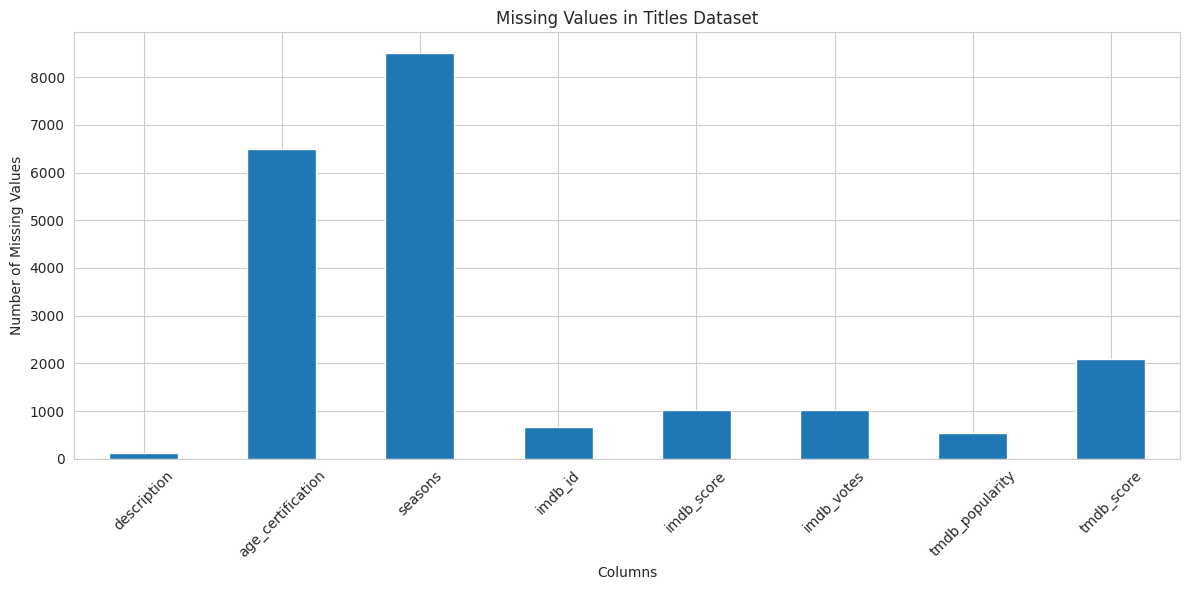

In [ ]:
# Visualizing the missing values

# Visualize missing values in the Titles dataset

plt.figure(figsize=(12, 6))

# Count missing values for each column
missing_values = titles.isnull().sum()

# Create bar chart
missing_values[missing_values > 0].plot(kind='bar')

plt.title("Missing Values in Titles Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

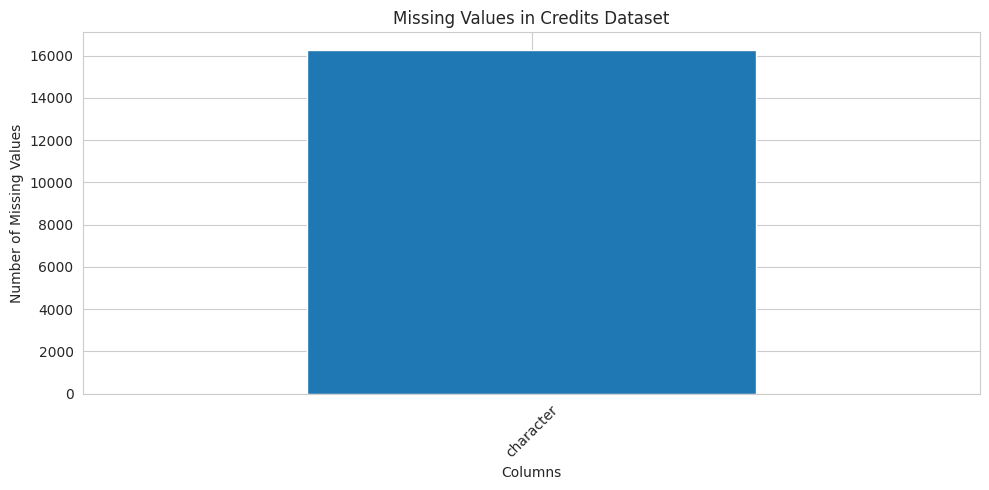

In [ ]:
# Visualize missing values in the Credits dataset

plt.figure(figsize=(10, 5))

# Count missing values for each column
missing_values = credits.isnull().sum()

# Create bar chart
missing_values[missing_values > 0].plot(kind='bar')

plt.title("Missing Values in Credits Dataset")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### What did you know about your dataset?



The dataset contains information about movies and TV shows available on Amazon Prime Video in the United States. It consists of two datasets: **titles.csv** and **credits.csv**.

The **Titles dataset** contains information about the content, such as title, show type, release year, age certification, runtime, genres, production countries, number of seasons, IMDb score, IMDb votes, TMDB popularity, and TMDB score.

The **Credits dataset** contains information about the people involved in the titles, including their name, character name, and role such as actor or director. Both datasets can be connected using the common **id** column.

From the initial exploration, we examined the dataset's rows, columns, data types, duplicate records, and missing values. We found that the dataset contains a mixture of **categorical, numerical, and text-based data**. Some columns contain missing values, which will need to be handled appropriately during the data-cleaning stage.

Overall, the dataset provides useful information for analyzing Amazon Prime Video's content distribution, genres, regional production, ratings, popularity, audience engagement, and trends over time.


## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns

# Display all columns in the Titles dataset

print("Columns in Titles Dataset:")
print(titles.columns)



Columns in Titles Dataset:
Index(['id', 'title', 'type', 'description', 'release_year',
       'age_certification', 'runtime', 'genres', 'production_countries',
       'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity',
       'tmdb_score'],
      dtype='object')


In [ ]:
# Display Credits dataset columns one by one

# Display all columns in the Credits dataset

print("Columns in Credits Dataset:")
print(credits.columns)

Columns in Credits Dataset:
Index(['person_id', 'id', 'name', 'character', 'role'], dtype='object')


In [ ]:
# Dataset Describe

# Generate descriptive statistics for the Titles dataset

print("----- Titles Dataset Description -----")
display(titles.describe())



----- Titles Dataset Description -----


,release_year,runtime,seasons,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
count,9871.000000,9871.000000,1357.000000,8850.000000,8.840000e+03,9324.000000,7789.000000
mean,2001.327221,85.973052,2.791452,5.976395,8.533614e+03,6.910204,5.984247
std,25.810071,33.512466,4.148958,1.343842,4.592015e+04,30.004098,1.517986
min,1912.000000,1.000000,1.000000,1.100000,5.000000e+00,0.000011,0.800000
25%,1995.500000,65.000000,1.000000,5.100000,1.170000e+02,1.232000,5.100000
50%,2014.000000,89.000000,1.000000,6.100000,4.625000e+02,2.536000,6.000000
75%,2018.000000,102.000000,3.000000,6.900000,2.236250e+03,5.634000,6.900000
max,2022.000000,549.000000,51.000000,9.900000,1.133692e+06,1437.906000,10.000000


In [ ]:
# Generate descriptive statistics for the Credits dataset

print("----- Credits Dataset Description -----")
display(credits.describe())

----- Credits Dataset Description -----


,person_id
count,1.242350e+05
mean,4.064737e+05
std,5.616296e+05
min,1.000000e+00
25%,3.899200e+04
50%,1.339490e+05
75%,5.712560e+05
max,2.371153e+06


### Variables Description

Titles Dataset

| Variable               | Description                                     |
| ---------------------- | ----------------------------------------------- |
| `id`                   | Unique ID assigned to each title on JustWatch.  |
| `title`                | Name of the movie or TV show.                   |
| `type`            | Type of content: Movie or TV Show.              |
| `description`          | Brief description or summary of the title.      |
| `release_year`         | Year in which the title was released.           |
| `age_certification`    | Age rating/certification assigned to the title. |
| `runtime`              | Runtime of the movie or the episode in minutes. |
| `genres`               | Genre or genres associated with the title.      |
| `production_countries` | Countries involved in producing the title.      |
| `seasons`              | Number of seasons for a TV show.                |
| `imdb_id`              | Unique ID of the title on IMDb.                 |
| `imdb_score`           | IMDb rating/score of the title.                 |
| `imdb_votes`           | Number of votes received by the title on IMDb.  |
| `tmdb_popularity`      | Popularity score of the title on TMDB.          |
| `tmdb_score`           | Rating/score of the title on TMDB.              |


Credits Dataset

| Variable         | Description                                    |
| ---------------- | ---------------------------------------------- |
| `person_id`      | Unique ID assigned to the person on JustWatch. |
| `id`             | ID of the title associated with the person.    |
| `name`           | Name of the actor or director.                 |
| `character` | Name of the character played by the actor.     |
| `role`           | Role of the person, such as Actor or Director. |


### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.

# unique values in each column of the Titles dataset

print("----- Unique Values in Titles Dataset -----")
print(titles.nunique())


----- Unique Values in Titles Dataset -----
id                      9868
title                   9737
type                       2
description             9734
release_year             110
age_certification         11
runtime                  207
genres                  2028
production_countries     497
seasons                   32
imdb_id                 9201
imdb_score                86
imdb_votes              3650
tmdb_popularity         5325
tmdb_score                89
dtype: int64


In [ ]:
# unique values in each column of the Credits dataset

print("----- Unique Values in Credits Dataset -----")
print(credits.nunique())

----- Unique Values in Credits Dataset -----
person_id    80508
id            8861
name         79758
character    71097
role             2
dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.

# Make copies of the original datasets before performing data wrangling.
# This keeps the original data safe and allows us to compare the changes later.

titles_clean = titles.copy()
credits_clean = credits.copy()

# Remove completely duplicate rows from both datasets.
titles_clean = titles_clean.drop_duplicates()
credits_clean = credits_clean.drop_duplicates()

# Remove leading and trailing spaces from column names.
titles_clean.columns = titles_clean.columns.str.strip()
credits_clean.columns = credits_clean.columns.str.strip()

# Display the updated shape after removing duplicate records.

print("Titles Dataset Shape after removing duplicates:", titles_clean.shape)
print("Credits Dataset Shape after removing duplicates:", credits_clean.shape)

Titles Dataset Shape after removing duplicates: (9868, 15)
Credits Dataset Shape after removing duplicates: (124179, 5)


In [ ]:

#For the titles dataset, some columns should be numeric:

# Convert numerical columns to appropriate numeric data types.
# errors='coerce' converts invalid values into NaN instead of causing an error.

numeric_columns = [
    'release_year',
    'runtime',
    'seasons',
    'imdb_score',
    'imdb_votes',
    'tmdb_popularity',
    'tmdb_score'
]

for column in numeric_columns:
    if column in titles_clean.columns:
        titles_clean[column] = pd.to_numeric(
            titles_clean[column],
            errors='coerce'
        )

# Display the data types after conversion
print(titles_clean.dtypes)

id                       object
title                    object
type                     object
description              object
release_year              int64
age_certification        object
runtime                 float64
genres                   object
production_countries     object
seasons                 float64
imdb_id                  object
imdb_score              float64
imdb_votes              float64
tmdb_popularity         float64
tmdb_score              float64
dtype: object


In [ ]:
# Check missing values in the titles dataset
print("Missing values in Titles Dataset:")
print(titles_clean.isnull().sum())

# Check missing values in the credits dataset
print("\nMissing values in Credits Dataset:")
print(credits_clean.isnull().sum())

Missing values in Titles Dataset:
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification          0
runtime                    0
genres                     0
production_countries       0
seasons                 8511
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2080
dtype: int64

Missing values in Credits Dataset:
person_id    0
id           0
name         0
character    0
role         0
dtype: int64


In [ ]:
# Calculate missing-value percentages
titles_missing = (titles_clean.isnull().mean() * 100).round(2)
credits_missing = (credits_clean.isnull().mean() * 100).round(2)

print("Missing Percentage in Titles Dataset:")
print(titles_missing)

print("\nMissing Percentage in Credits Dataset:")
print(credits_missing)

Missing Percentage in Titles Dataset:
id                       0.00
title                    0.00
type                     0.00
description              1.21
release_year             0.00
age_certification        0.00
runtime                  0.00
genres                   0.00
production_countries     0.00
seasons                 86.25
imdb_id                  6.76
imdb_score              10.35
imdb_votes              10.45
tmdb_popularity          5.54
tmdb_score              21.08
dtype: float64

Missing Percentage in Credits Dataset:
person_id    0.0
id           0.0
name         0.0
character    0.0
role         0.0
dtype: float64


In [ ]:
# Fill missing values in selected categorical columns
categorical_columns = [
    'show_type',
    'age_certification'
]

for column in categorical_columns:
    if column in titles_clean.columns:
        titles_clean[column] = titles_clean[column].fillna('Unknown')

# Fill missing values in selected credits columns
credits_text_columns = [
    'name',
    'character',
    'role'
]

for column in credits_text_columns:
    if column in credits_clean.columns:
        credits_clean[column] = credits_clean[column].fillna('Unknown')

In [ ]:
# Remove leading and trailing spaces from text columns
for column in titles_clean.select_dtypes(include='object').columns:
    titles_clean[column] = titles_clean[column].str.strip()

for column in credits_clean.select_dtypes(include='object').columns:
    credits_clean[column] = credits_clean[column].str.strip()

In [ ]:
# Standardize show_type values
if 'show_type' in titles_clean.columns:
    titles_clean['show_type'] = titles_clean['show_type'].str.upper()

# Standardize role values
if 'role' in credits_clean.columns:
    credits_clean['role'] = credits_clean['role'].str.upper()

# Check unique values
if 'show_type' in titles_clean.columns:
    print(titles_clean['show_type'].unique())

if 'role' in credits_clean.columns:
    print(credits_clean['role'].unique())

['ACTOR' 'DIRECTOR']


In [ ]:
# Check and handle invalid numerical values

if 'imdb_score' in titles_clean.columns:
    titles_clean.loc[
        ~titles_clean['imdb_score'].between(0, 10),
        'imdb_score'
    ] = np.nan

if 'tmdb_score' in titles_clean.columns:
    titles_clean.loc[
        ~titles_clean['tmdb_score'].between(0, 10),
        'tmdb_score'
    ] = np.nan

if 'runtime' in titles_clean.columns:
    titles_clean.loc[
        titles_clean['runtime'] <= 0,
        'runtime'
    ] = np.nan

if 'imdb_votes' in titles_clean.columns:
    titles_clean.loc[
        titles_clean['imdb_votes'] < 0,
        'imdb_votes'
    ] = np.nan

if 'tmdb_popularity' in titles_clean.columns:
    titles_clean.loc[
        titles_clean['tmdb_popularity'] < 0,
        'tmdb_popularity'
    ] = np.nan

if 'seasons' in titles_clean.columns:
    titles_clean.loc[
        titles_clean['seasons'] <= 0,
        'seasons'
    ] = np.nan

In [ ]:
# Check missing IDs in both datasets
print("Missing IDs in Titles:", titles_clean['id'].isnull().sum())
print("Missing IDs in Credits:", credits_clean['id'].isnull().sum())

Missing IDs in Titles: 0
Missing IDs in Credits: 0


In [ ]:
# Remove records with missing IDs
titles_clean = titles_clean.dropna(subset=['id'])
credits_clean = credits_clean.dropna(subset=['id'])

In [ ]:
# Display final dataset shapes
print("Final Titles Dataset Shape:", titles_clean.shape)
print("Final Credits Dataset Shape:", credits_clean.shape)

# Check remaining missing values
print("\nRemaining Missing Values in Titles:")
print(titles_clean.isnull().sum())

print("\nRemaining Missing Values in Credits:")
print(credits_clean.isnull().sum())

# Check final data types
print("\nFinal Titles Data Types:")
print(titles_clean.dtypes)

print("\nFinal Credits Data Types:")
print(credits_clean.dtypes)

Final Titles Dataset Shape: (9868, 15)
Final Credits Dataset Shape: (124179, 5)

Remaining Missing Values in Titles:
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification          0
runtime                    0
genres                     0
production_countries       0
seasons                 8511
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2080
dtype: int64

Remaining Missing Values in Credits:
person_id    0
id           0
name         0
character    0
role         0
dtype: int64

Final Titles Data Types:
id                       object
title                    object
type                     object
description              object
release_year              int64
age_certification        object
runtime                 float64
genres                   object
production_countries     ob

### What all manipulations have you done and insights you found?

The following operations were performed:

1. Creating Dataset Copies: Created copies of the original Titles and Credits datasets to preserve the original data.

2. Removing Duplicate Records: Removed duplicate rows from both datasets to avoid repeated records.

3. Cleaning Column Names: Removed unnecessary spaces from column names to maintain consistency.

4. Checking Missing Values: Identified missing values in both datasets to understand the completeness of the data.

5. Calculating Missing Value Percentage: Calculated the percentage of missing values in each column to understand the extent of missing data.

6. Handling Missing Values: Replaced missing values in selected categorical columns with "Unknown" to maintain consistency.

7. Removing Extra Spaces: Removed unnecessary leading and trailing spaces from text columns.

8. Standardizing Text Values: Standardized selected categorical values to maintain consistency across the datasets.

9. Checking Invalid Numerical Values: Checked numerical columns for invalid values, such as negative runtime, negative votes, and scores outside the expected range.

10. Converting Data Types: Converted columns such as release year, runtime, seasons, IMDb score, IMDb votes, TMDB popularity, and TMDB score into appropriate numeric data types using pd.to_numeric().

Insights from Data Wrangling

* Identified duplicate records in the datasets and removed them.

* Observed missing values in different columns.

* Identified text formatting and consistency issues.

* Checked numerical columns for invalid values.

* Prepared the datasets with cleaner column names and appropriate data types.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1  Distribution of Movies and TV Shows

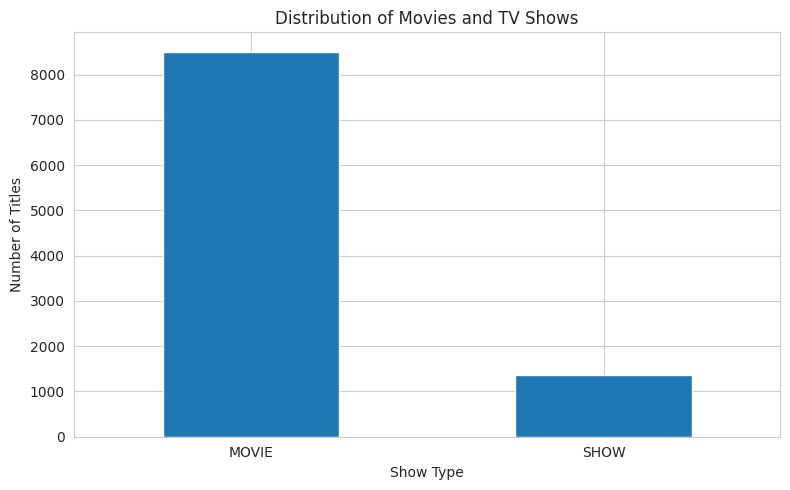

In [ ]:
# Chart 1: Distribution of Movies and TV Shows

plt.figure(figsize=(8, 5))

# Count the number of Movies and TV Shows using the correct column 'type'
show_type_count = titles_clean['type'].value_counts()

# Create a bar chart
show_type_count.plot(kind='bar')

# Add chart title and labels
plt.title('Distribution of Movies and TV Shows')
plt.xlabel('Show Type')
plt.ylabel('Number of Titles')

# Keep x-axis labels horizontal
plt.xticks(rotation=0)

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart was selected because the objective is to compare the number of titles between two categorical variables: Movies and TV Shows. A bar chart makes it easy to see which type of content is more available in the dataset.

##### 2. What is/are the insight(s) found from the chart?

* The chart shows the distribution of Movies and TV Shows available on Amazon Prime Video.
* It helps identify which content type has a higher number of titles.
* If Movies are higher, it indicates that the content library has a stronger focus on movies.
* If TV Shows are higher, it indicates a greater availability of episodic content.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This insight can help Amazon understand the current content mix and make better content-planning decisions. For example, if movies dominate the library, Amazon can evaluate whether increasing high-quality TV Shows could improve viewer engagement and retention. Similarly, if TV Shows dominate, Amazon can continue investing in successful series and episodic content.

Possible negative growth insight:

If one content type is significantly higher than the other, it may indicate an imbalance in the content library. For example, having a very large number of movies but comparatively fewer TV Shows could mean limited variety for viewers who prefer long-running series. This may reduce engagement among that audience and potentially affect customer retention. However, the chart alone does not prove negative growth; it only identifies an area that may require further analysis.

#### Chart - 2

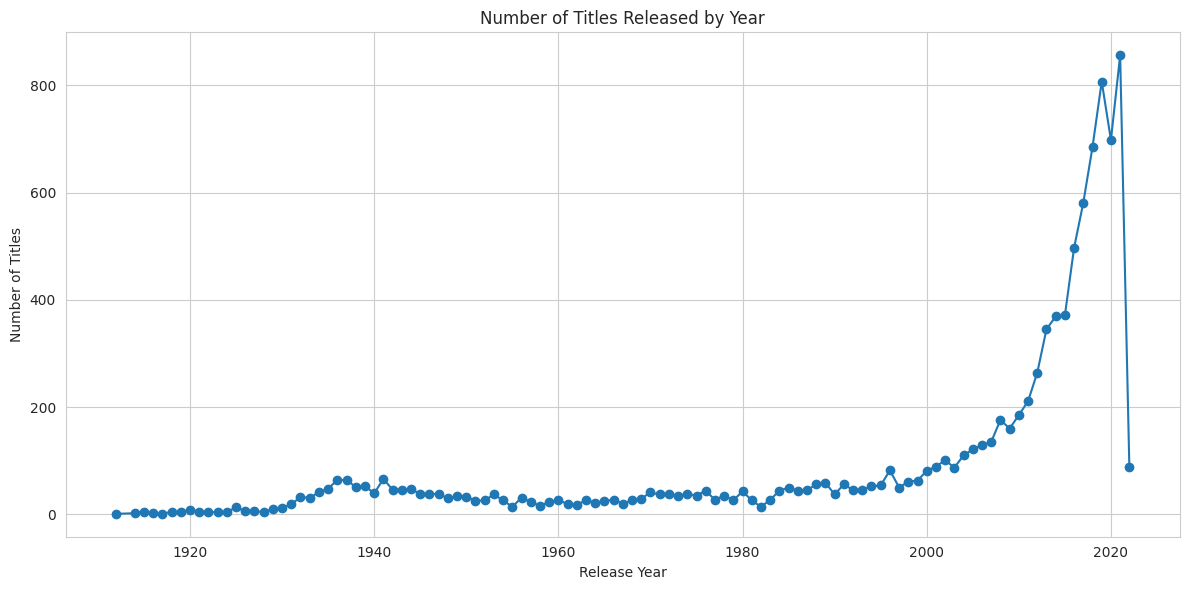

In [ ]:
# Chart 2: Number of Titles Released by Year

plt.figure(figsize=(12, 6))

# Count the number of titles released in each year
release_year_count = titles['release_year'].value_counts().sort_index()

# Create a line chart
release_year_count.plot(kind='line', marker='o')

# Add chart title and labels
plt.title('Number of Titles Released by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A line chart was selected because release_year is a time-based variable. A line chart is useful for showing the trend and changes in the number of titles released over different years.

##### 2. What is/are the insight(s) found from the chart?

* The chart shows how the number of titles released has changed over the years.

* It helps identify periods when content releases increased or decreased.

* A rising trend indicates increasing content production or availability.

* A declining trend in recent years may indicate fewer titles being added from those release years.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The insights can help Amazon understand content trends and plan future content investments. If the number of titles has increased over time, it indicates a growing content library and can provide viewers with more choices, potentially improving engagement and customer retention.

Possible negative growth insight:

If the chart shows a decline in titles during recent years, it may indicate a reduction in newer content. This could negatively affect viewer interest because customers generally expect fresh and regularly updated content. Amazon may need to invest in newer movies and TV shows to maintain engagement and competitiveness.

#### Chart - 3

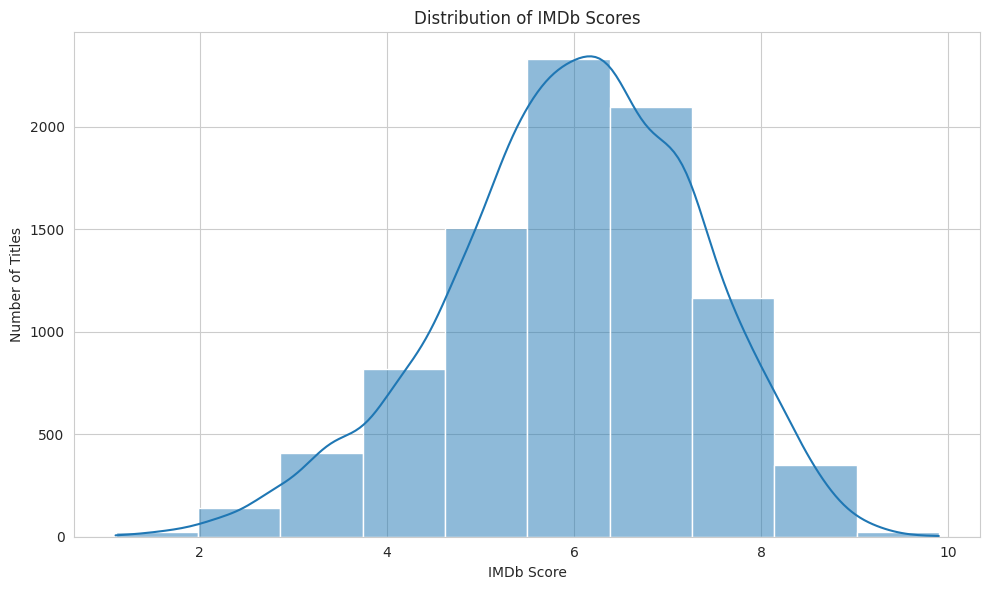

In [ ]:
# Chart 3: Distribution of IMDb Scores

plt.figure(figsize=(10, 6))

# Create a histogram of IMDb scores
sns.histplot(
    data=titles,
    x='imdb_score',
    bins=10,
    kde=True
)

# Add chart title and labels
plt.title('Distribution of IMDb Scores')
plt.xlabel('IMDb Score')
plt.ylabel('Number of Titles')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram was selected because imdb_score is a numerical variable. It helps show how IMDb ratings are distributed across all the titles and makes it easy to identify where most of the ratings are concentrated.

##### 2. What is/are the insight(s) found from the chart?

* The chart shows the distribution of IMDb ratings for the titles.

* Most titles are concentrated within a particular range of IMDb scores.

* It helps identify whether the Prime Video content library generally contains low-rated, average-rated, or highly-rated titles.

* The distribution can also show whether there are very few titles with extremely high or extremely low ratings

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. IMDb score distribution can help Amazon understand the overall quality of its content library. If a large proportion of titles have good ratings, it can indicate strong content quality, which may improve customer satisfaction and engagement. Amazon can also use this information when deciding which types of content to promote or invest in.

Possible negative growth insight:

If a large number of titles have low IMDb scores, it may indicate that some content is not well received by viewers. Promoting too much low-rated content could reduce customer satisfaction and engagement, which may negatively affect customer retention. Therefore, Amazon can focus more on acquiring or producing high-quality content.

#### Chart - 4

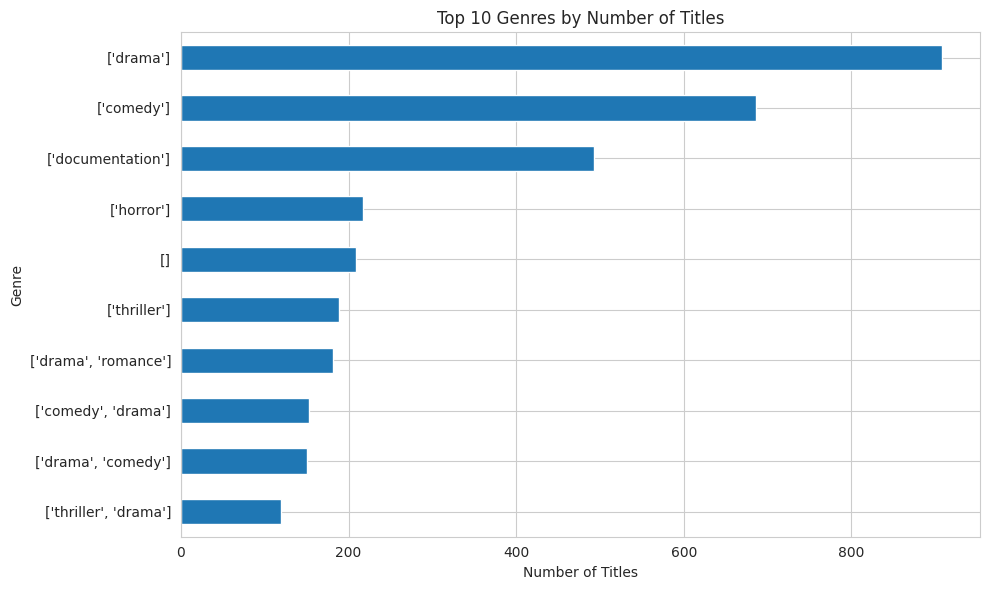

In [ ]:
# Chart 4: Top 10 Genres

plt.figure(figsize=(10, 6))

# Count the number of titles for each genre
genre_count = titles['genres'].value_counts().head(10)

# Create a horizontal bar chart
genre_count.sort_values().plot(kind='barh')

# Add chart title and labels
plt.title('Top 10 Genres by Number of Titles')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a horizontal bar chart because the genres variable is categorical. A bar chart makes it easy to compare the number of titles across different genres. A horizontal layout also makes long genre names easier to read.

##### 2. What is/are the insight(s) found from the chart?

* The chart shows the top 10 genres based on the number of titles.

* It helps identify which genres have the largest presence in the Amazon Prime Video content library.

* Genres with higher counts indicate that Prime Video has a stronger content presence in those categories.

* Genres with lower counts among the top 10 may represent comparatively smaller content categories.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help Amazon Prime Video understand which genres have a strong presence in its content library. This can support content planning, acquisition, production, and audience targeting.

For example, if a particular genre has a large number of titles, Amazon can continue investing in that category while also checking whether audience demand supports the investment.

Possible negative business impact:

If the library is heavily concentrated in only a few genres, it may reduce content diversity. This could limit choices for users with different preferences and potentially affect user engagement and retention. Therefore, Prime Video should maintain a balance between popular genres and less-represented genres.

#### Chart - 5

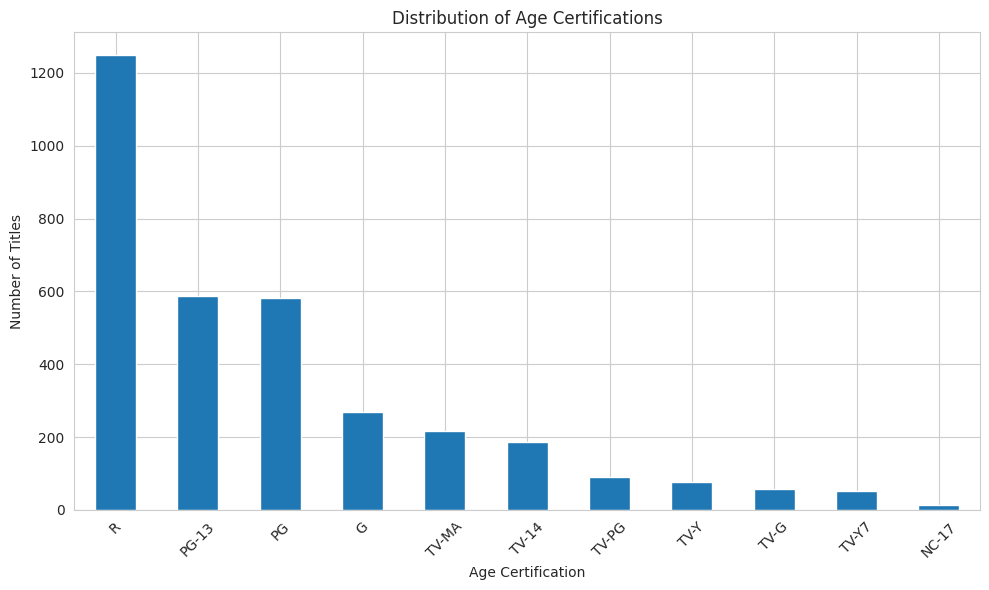

In [ ]:
# Chart 5: Distribution of Age Certifications

plt.figure(figsize=(10, 6))

# Count the number of titles for each age certification
age_certification_count = titles['age_certification'].value_counts(dropna=True)

# Create a bar chart
age_certification_count.plot(kind='bar')

# Add chart title and labels
plt.title('Distribution of Age Certifications')
plt.xlabel('Age Certification')
plt.ylabel('Number of Titles')

# Rotate labels for better readability
plt.xticks(rotation=45)

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because age_certification is a categorical variable. The bar chart makes it easy to compare the number of titles available under different age certifications.

##### 2. What is/are the insight(s) found from the chart?

* The chart shows the distribution of titles across different age certification categories.

* It helps identify which age groups have the highest number of titles.

* It also shows whether the Prime Video library is more focused on general audiences, teenagers, or mature audiences.

* Categories with fewer titles indicate areas where the content library has comparatively less representation.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help Amazon Prime Video understand its target audience distribution and plan future content accordingly. It can support decisions related to content acquisition, production, recommendations, and audience targeting.

Are there any insights that lead to negative growth?

Yes, if the content is heavily concentrated in only one age category, it could limit the platform's appeal to other audience groups.

For example, if mature-rated content dominates, family-oriented users may have fewer suitable choices. Similarly, if family content dominates, adult viewers may find fewer suitable options. Maintaining a balanced age-certification mix can help Prime Video serve a wider audience and improve user engagement and

#### Chart - 6

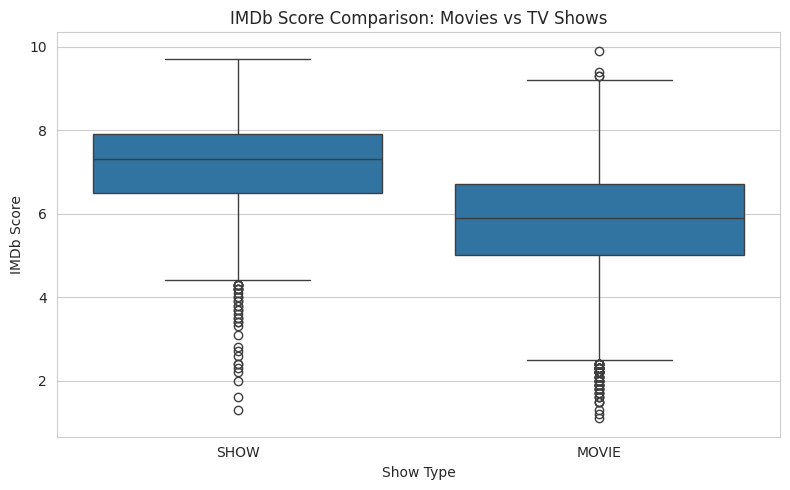

In [ ]:
# Chart 6: Show Type vs IMDb Score

plt.figure(figsize=(8, 5))

# Create a box plot to compare IMDb scores of Movies and TV Shows
sns.boxplot(data=titles, x='type', y='imdb_score')

# Add chart title and labels
plt.title('IMDb Score Comparison: Movies vs TV Shows')
plt.xlabel('Show Type')
plt.ylabel('IMDb Score')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a box plot because it helps compare the IMDb score distributions of Movies and TV Shows. It displays the median score, spread of scores, and potential outliers for both categories.

##### 2. What is/are the insight(s) found from the chart?

* The chart compares the IMDb scores of Movies and TV Shows.

* It helps identify which type has a higher median IMDb score.

* It shows how widely ratings vary within each category.

* It also helps identify titles with unusually high or low ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help Amazon Prime Video evaluate audience-rated content quality and make better decisions about content acquisition, production, and promotion.

For example, if TV Shows have a higher median IMDb score, Prime Video could investigate successful series and consider investing in similar content.

Are there any insights that lead to negative growth?

If one content category has consistently lower ratings, it may indicate a need to review content quality in that category. Poorly rated content may receive less audience interest and could affect viewer satisfaction.

However, lower IMDb scores alone do not prove negative business growth. Prime Video should also consider viewing figures, audience demand, genre preferences, and customer retention before making investment decisions.

#### Chart - 7

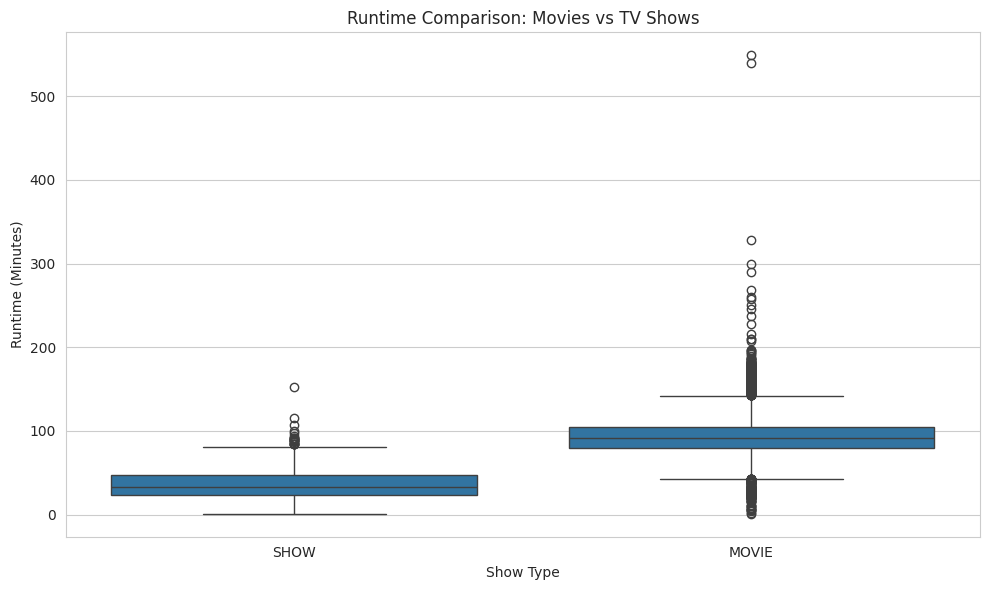

In [ ]:
# Chart 7: Show Type vs Runtime

plt.figure(figsize=(10, 6))

# Compare runtime distributions for Movies and TV Shows
sns.boxplot(data=titles, x='type', y='runtime')

# Add chart title and labels
plt.title('Runtime Comparison: Movies vs TV Shows')
plt.xlabel('Show Type')
plt.ylabel('Runtime (Minutes)')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a box plot because it helps compare the runtime distributions of Movies and TV Shows. It shows the median runtime, spread of values, and potential outliers for each category.

##### 2. What is/are the insight(s) found from the chart?

* The chart compares the runtime of Movies and TV Shows.

* It helps identify which category has a higher median runtime.

* It shows how much runtime varies within each category.

* It identifies titles with unusually short or long runtimes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help Amazon Prime Video understand content duration and plan content that suits different viewing preferences. For example, runtime analysis can support decisions about acquiring movies of different lengths and producing TV episodes suited to audience viewing habits.

Are there any insights that lead to negative growth?

If a category has runtimes that do not match audience preferences, viewers may be less satisfied or may stop watching content early. For example, very long movies may not suit viewers looking for shorter entertainment.

However, runtime alone does not prove negative business growth. Prime Video should also consider viewer completion rates, engagement, and audience feedback before changing its content strategy.

#### Chart - 8

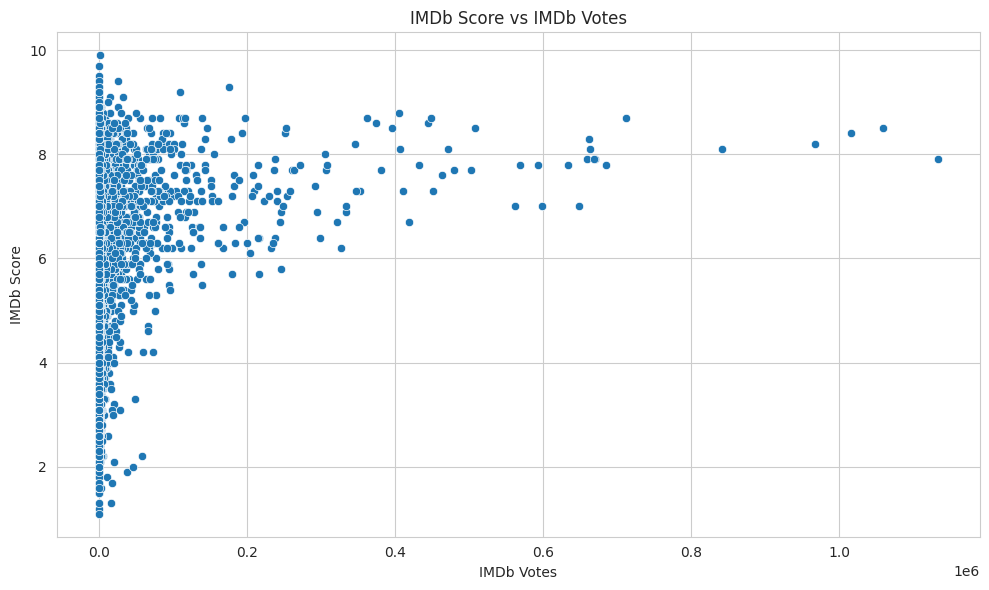

In [ ]:
# Chart 8: IMDb Score vs IMDb Votes

plt.figure(figsize=(10, 6))

# Create a scatter plot to examine the relationship between scores and votes
sns.scatterplot(
    data=titles,
    x='imdb_votes',
    y='imdb_score'
)

# Add chart title and labels
plt.title('IMDb Score vs IMDb Votes')
plt.xlabel('IMDb Votes')
plt.ylabel('IMDb Score')


# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot because both imdb_score and imdb_votes are numerical variables. A scatter plot helps visualize the relationship between IMDb ratings and the number of votes received by each title.

##### 2. What is/are the insight(s) found from the chart?

* The chart shows whether titles with more IMDb votes tend to receive higher or lower ratings.

* It helps identify titles with high ratings and a large number of votes.

* It highlights titles with many votes but relatively low ratings.

* It may reveal a positive, negative, or weak relationship between IMDb scores and votes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help Amazon Prime Video identify titles that receive substantial audience attention and have strong ratings. This information can support content promotion, acquisition, and future investment decisions.

For example, titles with both high ratings and many votes could be studied to understand which genres or content characteristics appeal to audiences.

Are there any insights that lead to negative growth?

Yes. If some titles receive many votes but have consistently low ratings, it may indicate that audience interest does not always translate into audience satisfaction. This could help identify content that needs further evaluation.

However, IMDb votes and ratings alone cannot prove negative business growth. Prime Video should also examine actual viewership, watch time, completion rates, and customer feedback before making business decisions.

#### Chart - 9

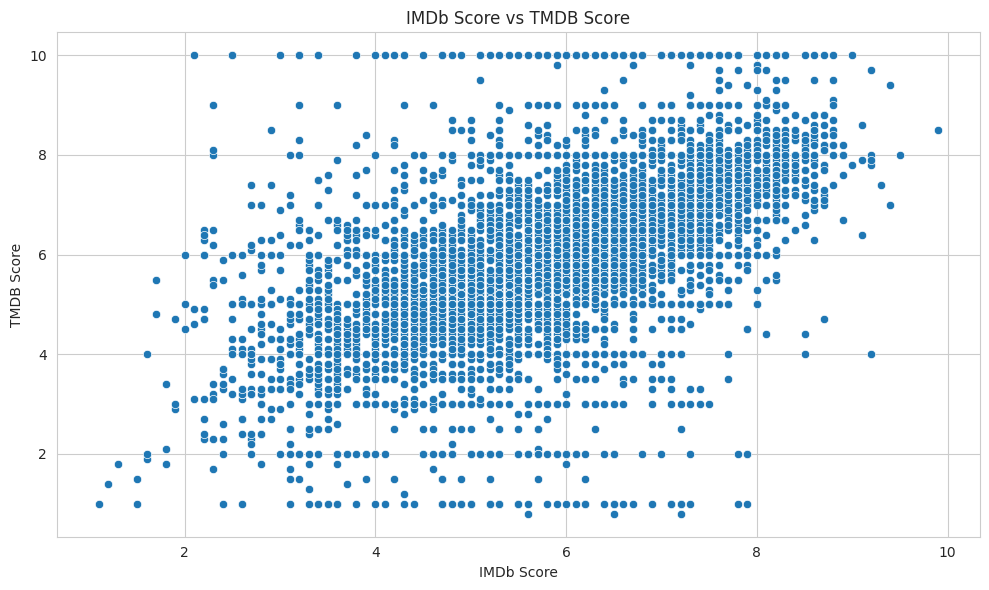

In [ ]:
# Chart 9: IMDb Score vs TMDB Score

plt.figure(figsize=(10, 6))

# Compare IMDb scores with TMDB scores
sns.scatterplot(
    data=titles,
    x='imdb_score',
    y='tmdb_score'
)

# Add chart title and labels
plt.title('IMDb Score vs TMDB Score')
plt.xlabel('IMDb Score')
plt.ylabel('TMDB Score')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot because both imdb_score and tmdb_score are numerical variables. It helps visualize the relationship between the ratings given by IMDb and TMDB for the same titles

##### 2. What is/are the insight(s) found from the chart?

* The chart helps identify whether IMDb and TMDB ratings show a positive relationship.

* If the points move upward from left to right, it indicates that titles with higher IMDb scores generally tend to have higher TMDB scores.

* Points far from the general pattern indicate titles where the two platforms' ratings differ.

* The chart helps compare rating patterns across the two platforms.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help Amazon Prime Video understand how consistently titles are rated across two platforms. Titles rated highly on both platforms may be strong candidates for promotion and further analysis.

This can support content evaluation, marketing decisions, and future content acquisition.

Are there any insights that lead to negative growth?

If some titles have high ratings on one platform but low ratings on the other, it may indicate differences in audience opinions or rating patterns. Relying on only one rating source could lead to poor content-selection or promotion decisions.

However, rating differences alone do not prove negative business growth. Prime Video should also consider audience engagement, viewing figures, and customer feedback before making decisions.

#### Chart - 10

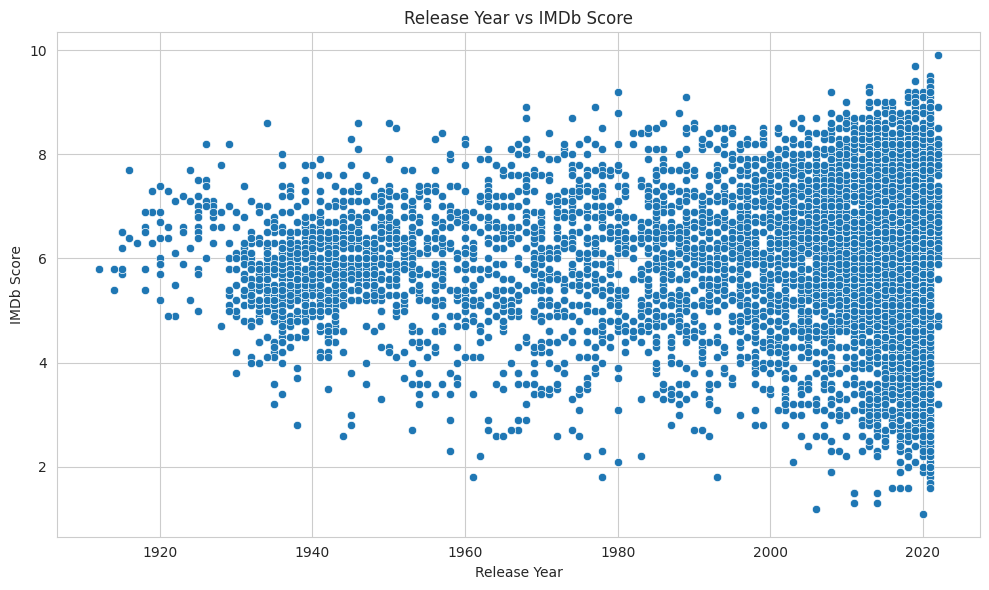

In [ ]:
# Chart 10: Release Year vs IMDb Score

plt.figure(figsize=(10, 6))

# Create a scatter plot to compare release years and IMDb scores
sns.scatterplot(
    data=titles,
    x='release_year',
    y='imdb_score'
)

# Add chart title and labels
plt.title('Release Year vs IMDb Score')
plt.xlabel('Release Year')
plt.ylabel('IMDb Score')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot because release_year and imdb_score are numerical variables. It helps visualize the relationship between a title's release year and its IMDb rating.

##### 2. What is/are the insight(s) found from the chart?

* The chart shows how IMDb scores are distributed across different release years.

* It helps identify whether highly rated titles are concentrated in particular periods.

* It shows whether older and newer titles have similar or different rating patterns.

* It may reveal unusual ratings or years with a wide range of scores.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. These insights can help Amazon Prime Video understand rating patterns across different release periods. The company can use this information alongside audience demand and viewing data to guide content acquisition, promotion, and library planning.

For example, if highly rated older titles are present in the library, Prime Video could consider promoting them to audiences who enjoy classic content.

Are there any insights that lead to negative growth?

If recent titles consistently receive lower ratings than titles from earlier periods, this could indicate a need to investigate content quality or audience preferences. Similarly, an underrepresentation of newer titles could suggest an opportunity to refresh the content library.

However, release year and IMDb score alone cannot prove negative business growth. Ratings, viewing figures, audience engagement, and the completeness of the dataset should all be considered before making business decisions.

#### Chart - 11

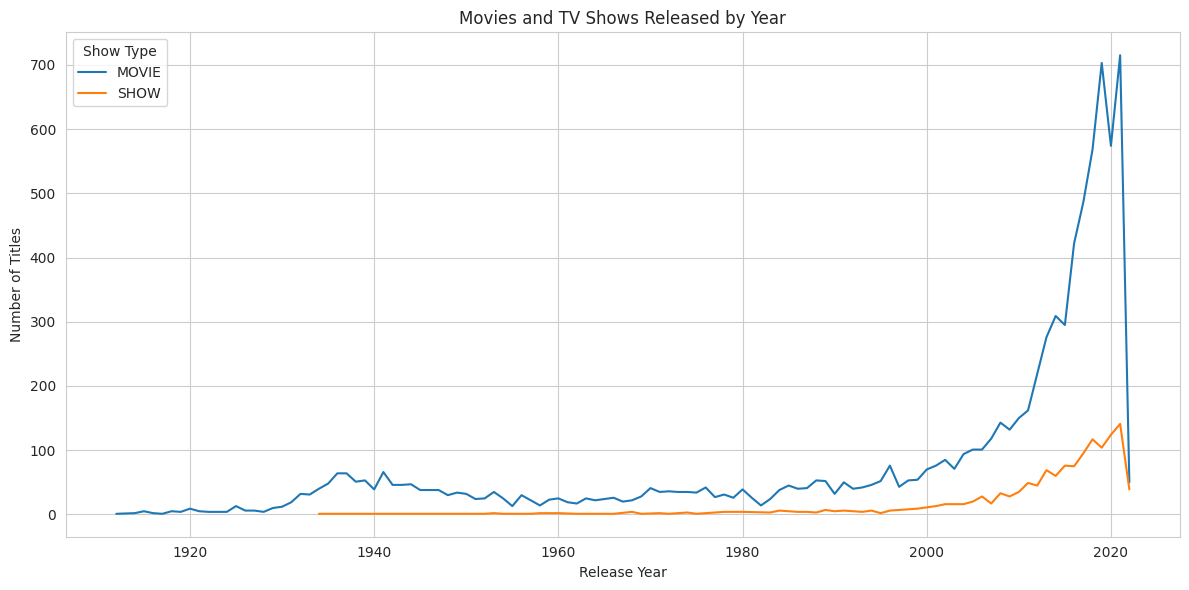

In [ ]:
# Chart 11: Release Year vs Show Type

plt.figure(figsize=(12, 6))

# Count titles released each year for each show type
yearly_count = titles.groupby(
    ['release_year', 'type']
).size().reset_index(name='title_count')

# Create a line chart
sns.lineplot(
    data=yearly_count,
    x='release_year',
    y='title_count',
    hue='type'
)

# Add chart title and labels
plt.title('Movies and TV Shows Released by Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.legend(title='Show Type')

# Display the chart
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a line chart because it clearly shows changes in the number of Movies and TV Shows released over different years. Different lines help compare both show types and identify release trends.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify which years had more Movies or TV Shows and how their release patterns changed over time. It also helps identify periods of growth or decline in the number of titles.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive business impact: Amazon Prime Video can use these trends to plan future content investments, maintain a balanced content library, and identify opportunities to add more Movies or TV Shows.

Potential negative impact: If the chart shows a decline in recent releases, viewers may have fewer new titles to explore. This could reduce engagement if the decline reflects an actual shortage of new content.

However, the latest years may be incomplete in the dataset. Therefore, a decline in the chart alone does not prove negative business growth.

#### Chart - 12

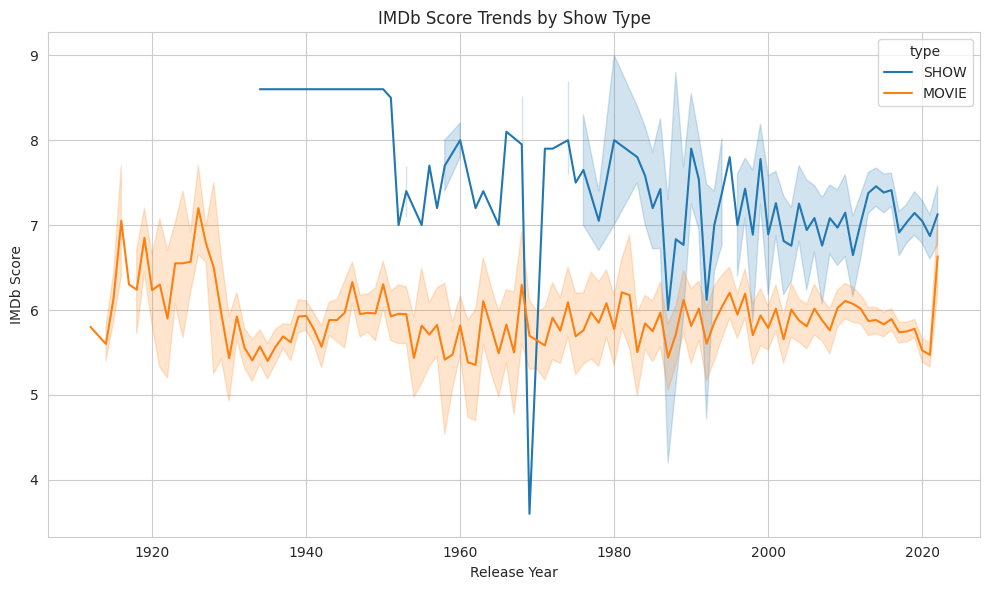

In [ ]:
# Chart 12: IMDb Score by Release Year and Show Type

plt.figure(figsize=(10, 6))

# Compare IMDb scores by year and show type
sns.lineplot(
    data=titles,
    x='release_year',
    y='imdb_score',
    hue='type'
)

# Add title and labels
plt.title('IMDb Score Trends by Show Type')
plt.xlabel('Release Year')
plt.ylabel('IMDb Score')

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a line chart because it shows how IMDb scores change over different release years. Different lines represent Movies and TV Shows, making it easy to compare their rating trends over time.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify whether IMDb scores for Movies and TV Shows increase or decrease over the years. It also helps compare which type of content tends to receive higher ratings in different periods.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive business impact: Amazon Prime Video can use these insights to identify content types and periods associated with higher ratings. This can support content acquisition, quality improvement, and future investment decisions.

Potential negative impact: If the chart shows declining IMDb scores for recent Movies or TV Shows, it may indicate a need to investigate content quality or changing audience preferences. Lower ratings could affect viewer interest.

However, IMDb scores alone do not prove negative business growth. Actual viewership, watch time, and audience retention should also be analyzed.

#### Chart - 13

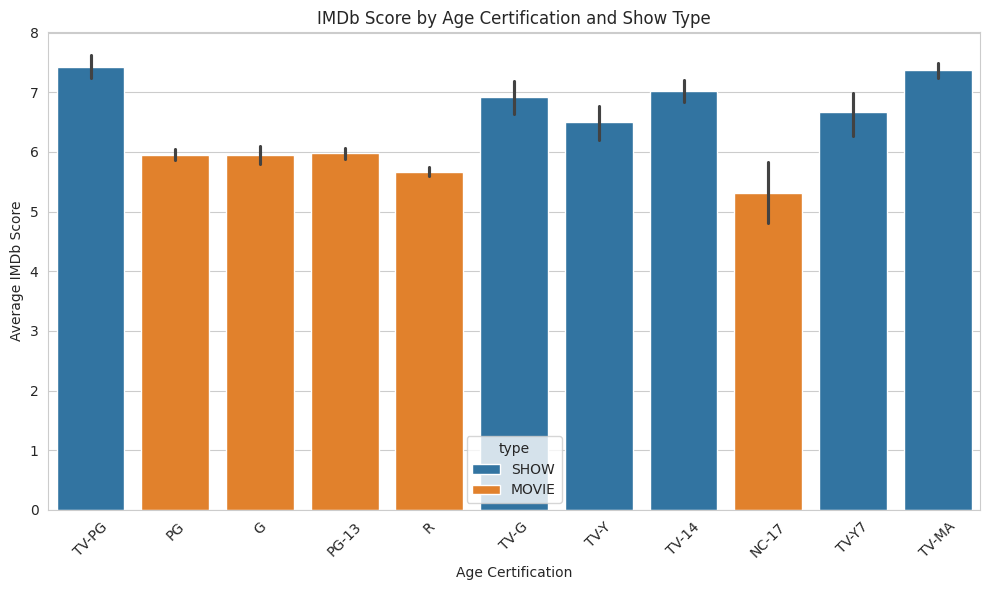

In [ ]:
# Chart 13: IMDb Score by Age Certification and Show Type

plt.figure(figsize=(10, 6))

# Compare IMDb scores by age certification and show type
sns.barplot(data=titles, x='age_certification', y='imdb_score', hue='type')

# Add title and labels
plt.title('IMDb Score by Age Certification and Show Type')
plt.xlabel('Age Certification')
plt.ylabel('Average IMDb Score')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it makes it easy to compare the average IMDb scores across different age-certification categories. Different colors represent Movies and TV Shows, allowing us to compare both types.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify which age-certification categories have higher average IMDb scores and whether Movies or TV Shows receive higher ratings within each category

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive business impact: Amazon Prime Video can use these insights to understand rating patterns across different audience categories and make better content acquisition, production, and recommendation decisions.

Potential negative impact: If certain age-certification categories consistently have lower average ratings, the company can investigate whether content quality or audience preferences need attention. If some audience categories have limited content, this may also indicate an opportunity to improve content variety.

However, lower IMDb scores alone do not prove negative business growth. Actual viewership, watch time, and audience retention should also be considered.

#### Chart - 14 - Correlation Heatmap

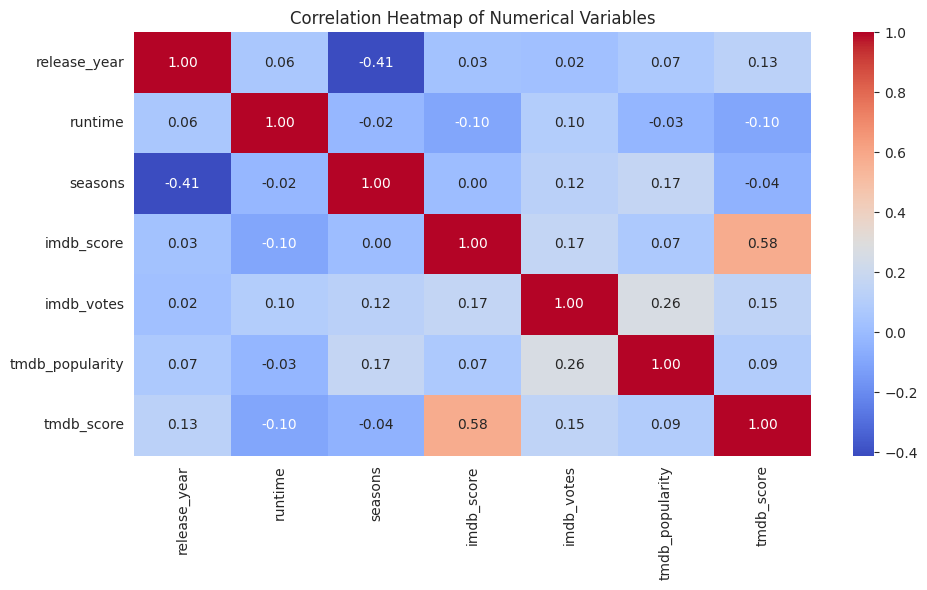

In [ ]:
# Chart 14: Correlation Heatmap

# Select numerical columns
numeric_data = titles[
    ['release_year', 'runtime', 'seasons',
     'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']
]

# Calculate correlation between numerical columns
correlation = numeric_data.corr()

# Create the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

# Add chart title
plt.title('Correlation Heatmap of Numerical Variables')

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a correlation heatmap because it shows the relationships between multiple numerical variables in one chart. The colors and correlation values make it easy to identify positive and negative relationships.

##### 2. What is/are the insight(s) found from the chart?

* Values closer to +1 indicate a strong positive correlation.

* Values closer to −1 indicate a strong negative correlation.

* Values closer to 0 indicate a weak linear relationship.

#### Chart - 15 - Pair Plot

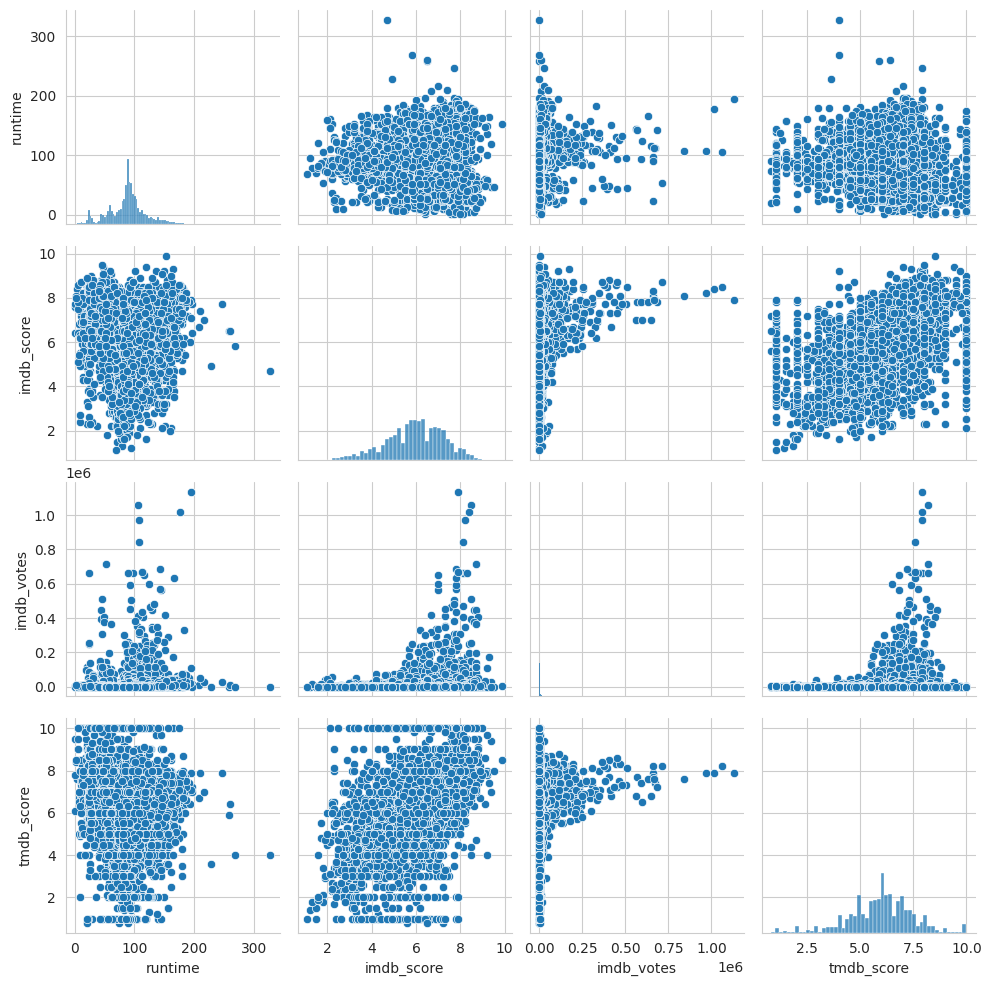

In [ ]:
# Chart 15: Pair Plot

# Select numerical columns for analysis
numeric_data = titles[
    ['runtime', 'imdb_score', 'imdb_votes', 'tmdb_score']
].dropna()

# Create the pair plot
sns.pairplot(numeric_data)

# Display the chart
plt.show()

##### 1. Why did you pick the specific chart?

I selected a pair plot because it helps visualize relationships between multiple numerical variables, such as runtime, IMDb score, IMDb votes, and TMDB score. It also shows the distribution of each variable, making it easier to identify patterns and unusual values

##### 2. What is/are the insight(s) found from the chart?

* It helps identify relationships between IMDb scores and TMDB scores.

* It shows whether titles with more IMDb votes tend to have higher or lower ratings.

* It helps identify patterns in runtime and ratings.

* It highlights unusual values and the distribution of numerical variables.

#### Chart - 16

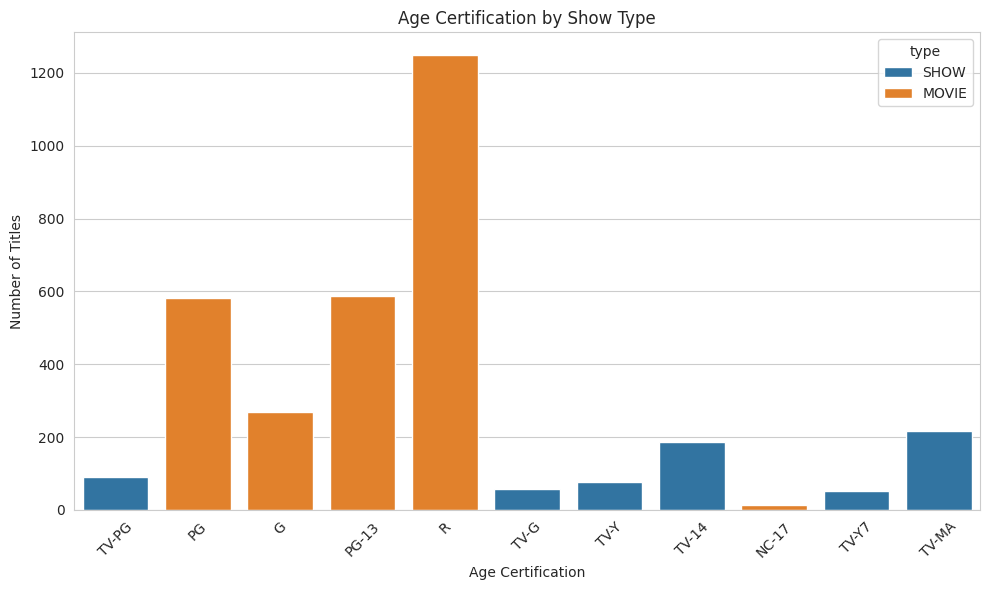

In [ ]:
# Chart 16: Age Certification by Show Type

plt.figure(figsize=(10, 6))

# Compare age certifications for Movies and TV Shows
sns.countplot(data=titles, x='age_certification', hue='type')

# Add title and labels
plt.title('Age Certification by Show Type')
plt.xlabel('Age Certification')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?


I selected a grouped bar chart because it makes it easy to compare age-certification categories between Movies and TV Shows. Different colors represent each show type, making the comparison clear.

##### 2. What is/are the insight(s) found from the chart?

* It identifies which age-certification categories have the highest and lowest numbers of titles.

* It shows how the distribution of age certifications differs between Movies and TV Shows.

* It helps identify audience categories that may have fewer content choices.

##### 3. Will the gained insights help creating a positive business impact?

   Are there any insights that lead to negative growth? Justify with specific reason

Positive business impact: Amazon Prime Video can use these insights to understand its content distribution and plan suitable Movies and TV Shows for different audience groups.

Potential negative impact: If certain age-certification categories contain very few titles, some audience groups may have limited choices. This could reduce viewer satisfaction if the available content does not meet their preferences.

However, a lower title count does not automatically mean negative business growth. Viewership, audience demand, and retention data should also be considered before making business decisions.

#### Chart - 17

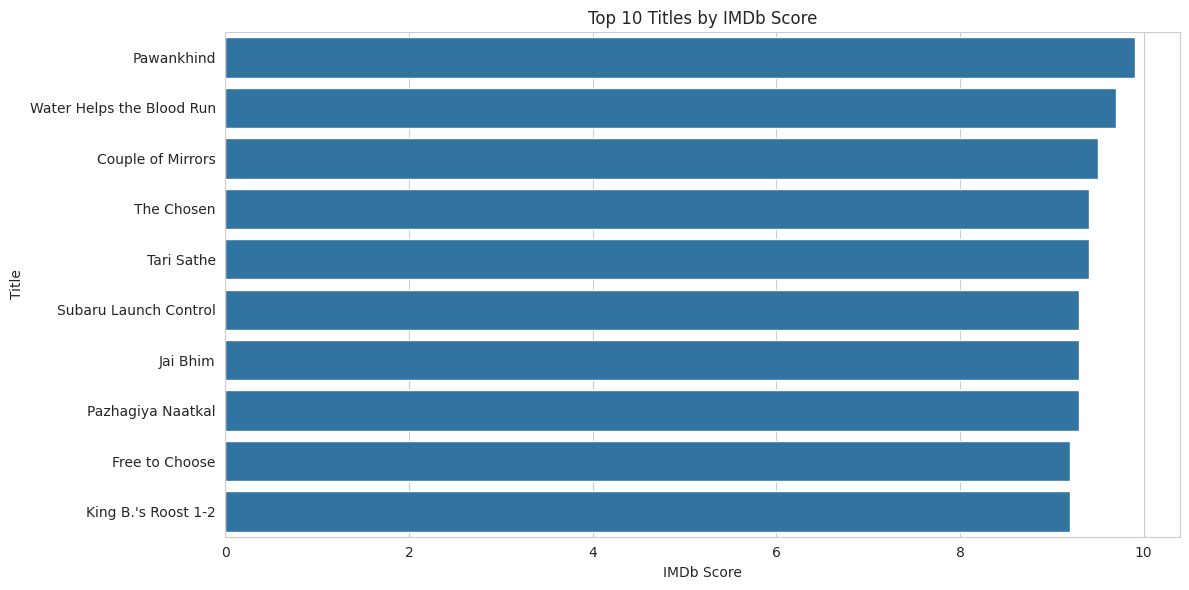

In [ ]:
# Chart 17: Top 10 Titles by IMDb Score

# Select the top 10 highest-rated titles
top_titles = titles.nlargest(10, 'imdb_score')

# Create a bar chart
plt.figure(figsize=(12, 6))
sns.barplot(data=top_titles, x='imdb_score', y='title')

# Add title and labels
plt.title('Top 10 Titles by IMDb Score')
plt.xlabel('IMDb Score')
plt.ylabel('Title')

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a horizontal bar chart because it makes it easy to compare the IMDb scores of the top 10 highest-rated titles. It also displays long title names clearly, making the chart easier to understand.

##### 2. What is/are the insight(s) found from the chart?

* It identifies the top 10 highest-rated titles in the dataset.



* It shows which titles received the highest IMDb scores.



* It helps compare the ratings of different titles and identify highly rated content.

##### 3. Will the gained insights help creating a positive business impact?
   
   Are there any insights that lead to negative growth? Justify with specific reason

Positive business impact: Amazon Prime Video can use highly rated titles in promotional campaigns and recommendations to attract viewers and improve engagement.

Potential negative impact: If only a small number of titles receive high ratings, the company could investigate opportunities to improve content quality across its library. However, this chart alone cannot prove negative business growth.

IMDb ratings do not directly measure actual viewership or profitability. Therefore, viewing figures, watch time, and audience retention should also be considered before making business decisions.

#### Chart - 18

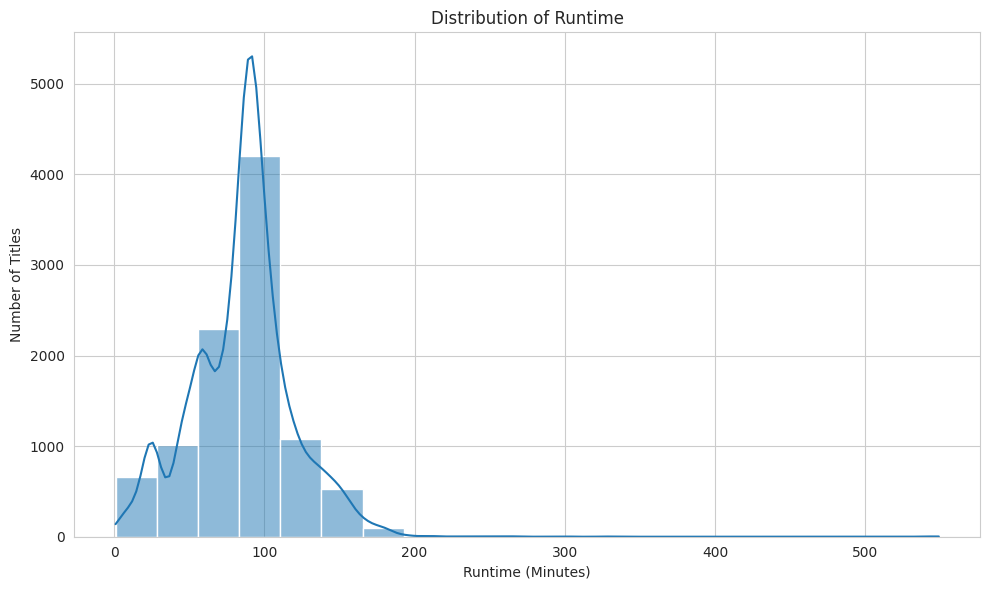

In [ ]:
# Chart 18: Distribution of Runtime

plt.figure(figsize=(10, 6))

# Create a histogram to show runtime distribution
sns.histplot(data=titles, x='runtime', bins=20, kde=True)

# Add title and labels
plt.title('Distribution of Runtime')
plt.xlabel('Runtime (Minutes)')
plt.ylabel('Number of Titles')

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

   I selected a histogram because it shows how runtime values are distributed across different ranges. It helps identify the most common content durations and makes it easy to observe variations in runtime.

##### 2. What is/are the insight(s) found from the chart?

* It identifies the runtime ranges containing the highest number of titles.



* It shows whether most titles have shorter, medium, or longer runtimes.



* It helps identify unusually short or long runtimes in the dataset.

##### 3. Will the gained insights help creating a positive business impact?

   Are there any insights that lead to negative growth? Justify with specific reason.

Positive business impact: Amazon Prime Video can use runtime patterns to understand its content library and offer a variety of content durations to suit different viewing preferences.

Potential negative impact: If the library has limited content in runtime ranges preferred by viewers, some audience needs may not be met. This could create an opportunity to improve content variety.

However, runtime alone does not prove negative business growth. Actual viewing behavior, watch time, and audience feedback should also be considered. Additionally, TV-show runtime may represent an episode rather than the entire series.

#### Chart - 19

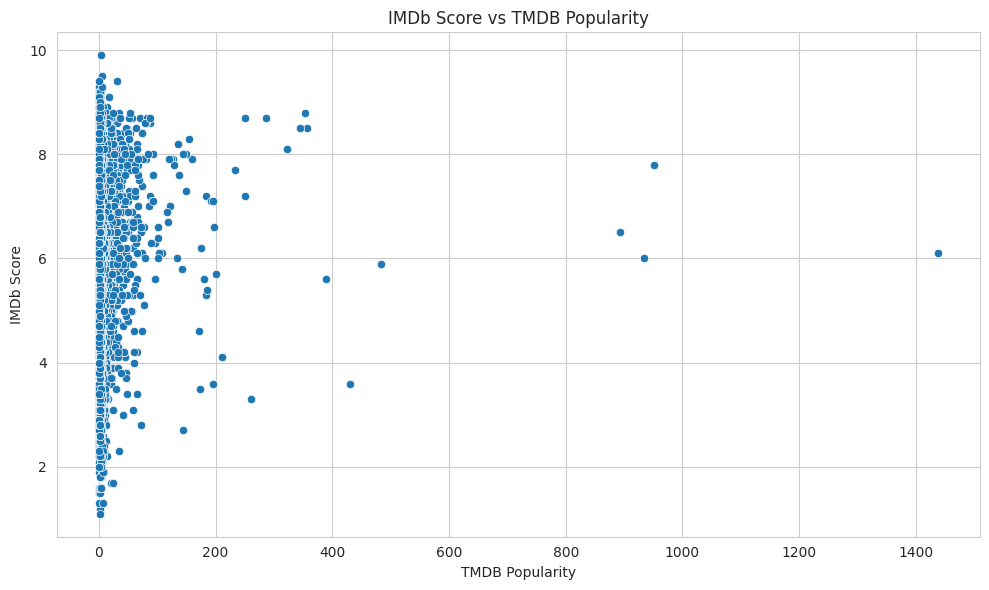

In [ ]:
# Chart 19: IMDb Score vs TMDB Popularity

plt.figure(figsize=(10, 6))

# Compare IMDb scores with TMDB popularity
sns.scatterplot(data=titles, x='tmdb_popularity', y='imdb_score')

# Add title and labels
plt.title('IMDb Score vs TMDB Popularity')
plt.xlabel('TMDB Popularity')
plt.ylabel('IMDb Score')

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a scatter plot because it helps visualize the relationship between two numerical variables: IMDb score and TMDB popularity. It makes it easy to identify patterns and unusual values.

##### 2. What is/are the insight(s) found from the chart?

* It shows whether titles with higher TMDB popularity tend to receive higher IMDb scores.



* It helps identify popular titles with high or low ratings.



* It shows whether popularity and ratings have a strong or weak relationship.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive business impact: Amazon Prime Video can use these insights to identify titles that have both high popularity and high ratings for potential promotional campaigns.

Potential negative impact: If some titles have high popularity but low IMDb scores, the company can investigate audience feedback and content quality to identify areas for improvement.

However, this does not automatically indicate negative business growth. TMDB popularity and IMDb ratings do not directly measure Prime Video views, watch time, or customer retention.

#### Chart - 20

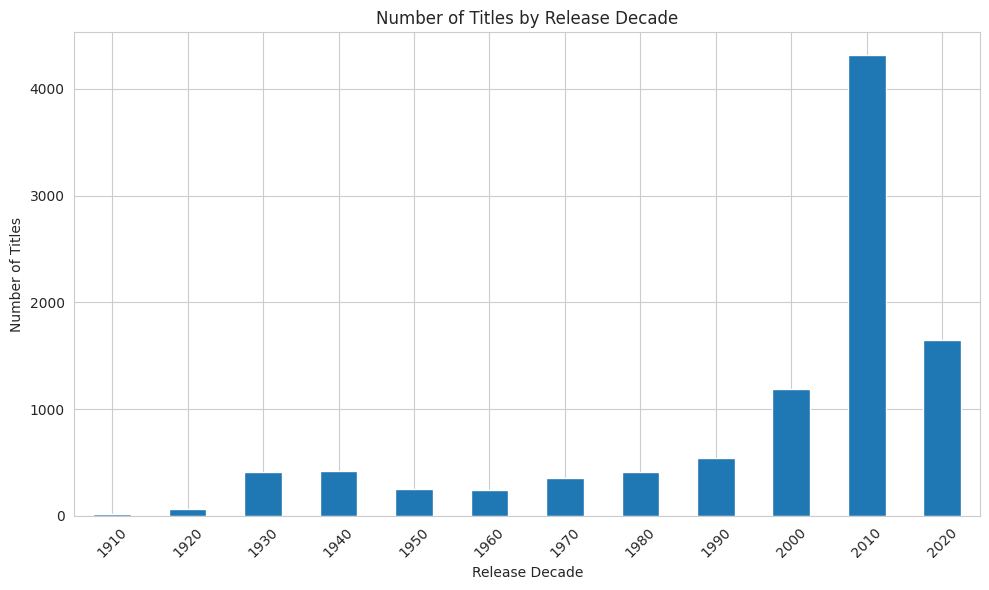

In [ ]:
# Chart 20: Number of Titles by Release Decade

# Group release years into decades
decade = (titles['release_year'] // 10 * 10)

# Count titles by decade
decade_count = decade.value_counts().sort_index()

# Create a bar chart
plt.figure(figsize=(10, 6))
decade_count.plot(kind='bar')

# Add title and labels
plt.title('Number of Titles by Release Decade')
plt.xlabel('Release Decade')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

I selected a bar chart because it makes it easy to compare the number of titles released across different decades. It helps present the distribution of older and newer content clearly.

##### 2. What is/are the insight(s) found from the chart?

* It identifies which decades have the highest and lowest numbers of titles.



* It shows how the content library is distributed across different time periods.



* It helps identify whether the dataset contains more older titles or newer titles.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive business impact: Amazon Prime Video can use these insights to plan its content library, promote popular older titles, and identify opportunities to add content from underrepresented decades.

Potential negative impact: If certain decades have very few titles, viewers interested in content from those periods may have fewer choices. This could indicate an opportunity to improve content variety.

However, fewer titles from a particular decade do not automatically mean negative business growth. Viewer demand, licensing costs, and actual viewing data should also be considered.

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

1. **Optimize Content Investment:** Identify genres with fewer titles and compare them with audience demand before acquiring or producing additional content. Prioritize genres that show strong viewer interest and good performance.

2. **Promote Highly Rated Titles:** Create promotional campaigns for titles with high IMDb ratings and sufficient vote counts. Feature these titles in recommendations and themed collections to increase content discovery.

3. **Improve Content Quality:** Identify titles with lower IMDb ratings and investigate audience feedback, genre, and content characteristics. Use these findings to guide future content acquisition and production decisions.

4. **Balance Movies and TV Shows:** Compare the number and performance of Movies and TV Shows. Adjust future content investments based on actual viewing figures, watch time, and audience preferences rather than title counts alone.

5. **Target Different Audience Groups:** Analyze age certifications and genres to identify content categories that may be underrepresented. Add suitable titles where audience demand supports the investment.

6. **Plan a Balanced Content Library:** Analyze release years and decades to identify gaps between older and newer titles. Promote relevant older titles and consider adding new releases based on audience interest and licensing costs.

7. **Measure Business Performance:** Track key metrics such as total views, watch time, completion rate, and subscriber retention alongside ratings and popularity indicators. Review these metrics regularly to evaluate whether content and promotional strategies are effective.



# **Conclusion**

The Exploratory Data Analysis (EDA) of Amazon Prime Video provided useful insights into its content library, including Movies and TV Shows, genres, release years, age certifications, runtime, IMDb ratings, and TMDB popularity. Using Python libraries such as Pandas, NumPy, Matplotlib, and Seaborn, the datasets were explored, cleaned, and visualized to identify patterns and relationships between variables.

The analysis helped understand content distribution, rating trends, and relationships between popularity and ratings. The visualizations also highlighted opportunities to improve content variety, promote highly rated titles, and make better data-driven content decisions.

Based on these findings, Amazon Prime Video can use actual viewing data, watch time, completion rates, audience feedback, and subscriber retention to evaluate content performance and improve future content investments. The recommendations can help the platform enhance audience engagement, strengthen content planning, and support sustainable business growth.

Overall, this project demonstrated how data analysis and visualization can transform raw datasets into meaningful insights that support business decision-making. However, conclusions about actual business performance should be validated using platform-specific viewing and subscription data, as ratings and popularity indicators alone cannot measure business success.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***